# Paket D — Öznitelik (7. adım), D6
7a: aynı yelek bilinen dönüşüm altında bulunuyor mu? 7b: SIFT noktaları nerede toplanıyor, HOG'da kenar yönleri yoğunlaşıyor mu?
Nokta sayısının çok olması tek başına başarı göstermez.

> Colab: defteri Drive'da açın (çift tık → *Birlikte aç → Google Colaboratory*). İlk hücre Drive'ı bağlar ve proje klasörünü kendisi bulur. Defterde yaptığınız değişiklik doğrudan Drive'daki dosyaya kaydedilir; *Drive'a kopya kaydet* **kullanmayın** (kopya "Colab Notebooks" klasörüne gider, grup göremez).

In [9]:
# --- Kurulum: Google Drive'ı bağlar ve proje klasörünü bulur (GitHub gerekmez) ---
PROJE = ''   # boş bırakın, otomatik bulunur; bulunamazsa Drive'daki yolu yazın: '/content/drive/MyDrive/.../yelek-tespiti'
import os, sys, glob, unicodedata
sys.dont_write_bytecode = True                      # Drive'daki src/ klasörüne __pycache__ yazılmasın

def _proje_mi(p):
    return os.path.isfile(os.path.join(p, 'src', 'common.py')) and os.path.isfile(os.path.join(p, 'config', 'params.json'))

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJE = PROJE.strip().rstrip('/')
    if PROJE and not _proje_mi(PROJE):               # Türkçe harf kodlaması farkı (ör. 'Ödevler')
        PROJE = next((unicodedata.normalize(f, PROJE) for f in ('NFC', 'NFD')
                      if _proje_mi(unicodedata.normalize(f, PROJE))), PROJE)
    if not PROJE:                                    # Drive'ım ve ortak drive'larda 4 klasör derinliğe kadar ara
        for d in range(5):
            bulunan = sorted({os.path.dirname(os.path.dirname(p))
                              for k in ('/content/drive/MyDrive', '/content/drive/Shareddrives')
                              for p in glob.glob(os.path.join(k, *['*'] * d, 'src', 'common.py'))})
            bulunan = [p for p in bulunan if _proje_mi(p)]
            if bulunan:
                PROJE = bulunan[0]
                if len(bulunan) > 1:
                    print('Birden fazla proje klasörü bulundu, ilki kullanılıyor:', *bulunan, sep='\n  ')
                break
    if not PROJE or not _proje_mi(PROJE):
        raise FileNotFoundError("Proje klasörü bulunamadı. Drive'da paylaşılan 'yelek-tespiti' klasörüne sağ tık -> "
                                "Düzenle -> Kısayol ekle -> Drive'ım; sonra bu hücreyi yeniden çalıştırın "
                                "(ya da yukarıda PROJE = '/content/drive/MyDrive/...' yazın).")
    os.chdir(PROJE)
elif os.path.basename(os.getcwd()) == 'notebooks':  # Colab dışında (Jupyter / VS Code)
    os.chdir('..')
sys.path.insert(0, os.path.join(os.getcwd(), 'src'))
try:                                                # Colab'ın Python 3.13 sürümünde autoreload bozuk; varsa açılır, yoksa geçilir
    get_ipython().run_line_magic('reload_ext', 'autoreload'); get_ipython().run_line_magic('autoreload', '2')
except Exception:
    pass
import warnings; warnings.filterwarnings('ignore')
%matplotlib inline
%config InlineBackend.figure_format = 'jpeg'   # defter boyutu küçük kalsın
from common import *
gt, P = load_gt(), load_params()
durum()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Proje klasörü : /content/drive/MyDrive/Yelek tespit deneme/yelek-tespiti-drive/yelek-tespiti
Görüntüler    : 20/20 hazır (data/images_1024)
gt.json       : 20 görüntü, 20 tanesinde kutu var
params dondu mu: True 2026-11-10T21:09:21
Kayıtlar      : 1 dosya kaydı, son: dondurma-2 (2026-11-10T21:09:21)


{
 "oran_testi": 0.75,
 "ransac_px": 3.0,
 "model": "homography",
 "kp_A": 188,
 "kp_B": 141,
 "gecen_eslesme": 73,
 "ic_deger": 64,
 "kose_hatasi_px": 0.4819289445877075,
 "kose_hatalari_px": [
  0.26,
  0.33,
  0.27,
  1.07
 ]
}


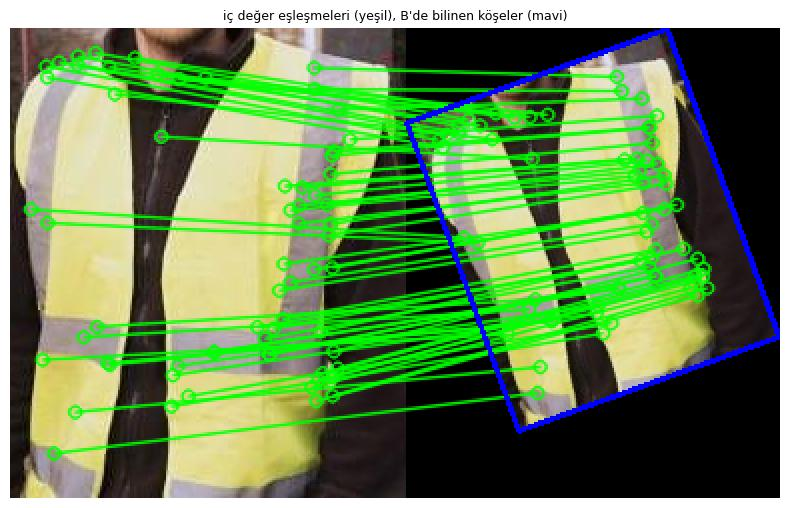

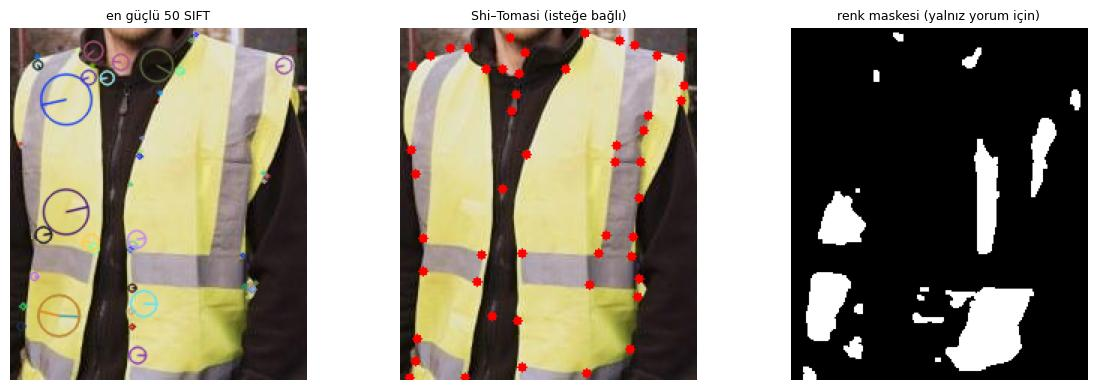

In [10]:
import features, json
P['features'].update(dev_id='G-1', vest_idx=0, angle_deg=20, scale=0.7, model='homography')
res, pair = features.run_all(P, gt, save=False)
print(json.dumps(res['7a'], ensure_ascii=False, indent=1))

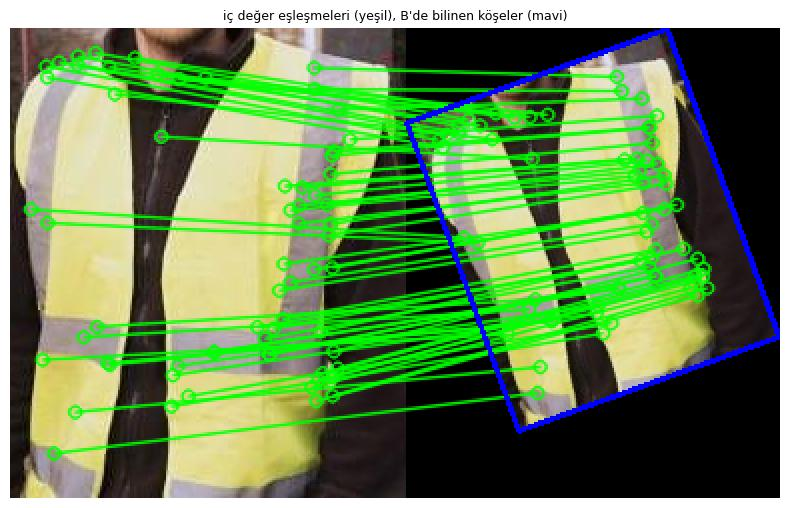

In [11]:
features.draw_matches(pair, path=RES / 'fig' / 'sift_matches.png');

## 7b — En güçlü 50 SIFT noktası ve HOG
Noktalar floresan kumaşta mı, şerit kenarlarında mı, fermuar/cep/yazıda mı? Düz bölge / kenar / köşe ayrımıyla açıklayın.
HOG çubuk grafiğinde 90° = yatay kenar (yatay şerit).

In [12]:
res['7b_sift']

{'top_k': 50,
 'yapi_tensoru': {'düz': 15, 'kenar': 29, 'köşe': 6},
 'renk_maskesi_ustunde': 3,
 '_not': 'Düz/kenar/köşe ayrımı yapı tensörü özdeğerleriyle yardımcı ölçüdür; görsel yorumla birlikte yazın.'}

{'G-1/P0': {'yelek': True,
  'yon_enerjisi': {10.0: 0.211,
   30.0: 0.121,
   50.0: 0.098,
   70.0: 0.09,
   90.0: 0.114,
   110.0: 0.088,
   130.0: 0.076,
   150.0: 0.075,
   170.0: 0.127}},
 'G-4/P0': {'yelek': False,
  'yon_enerjisi': {10.0: 0.149,
   30.0: 0.099,
   50.0: 0.097,
   70.0: 0.088,
   90.0: 0.137,
   110.0: 0.1,
   130.0: 0.106,
   150.0: 0.105,
   170.0: 0.119}}}

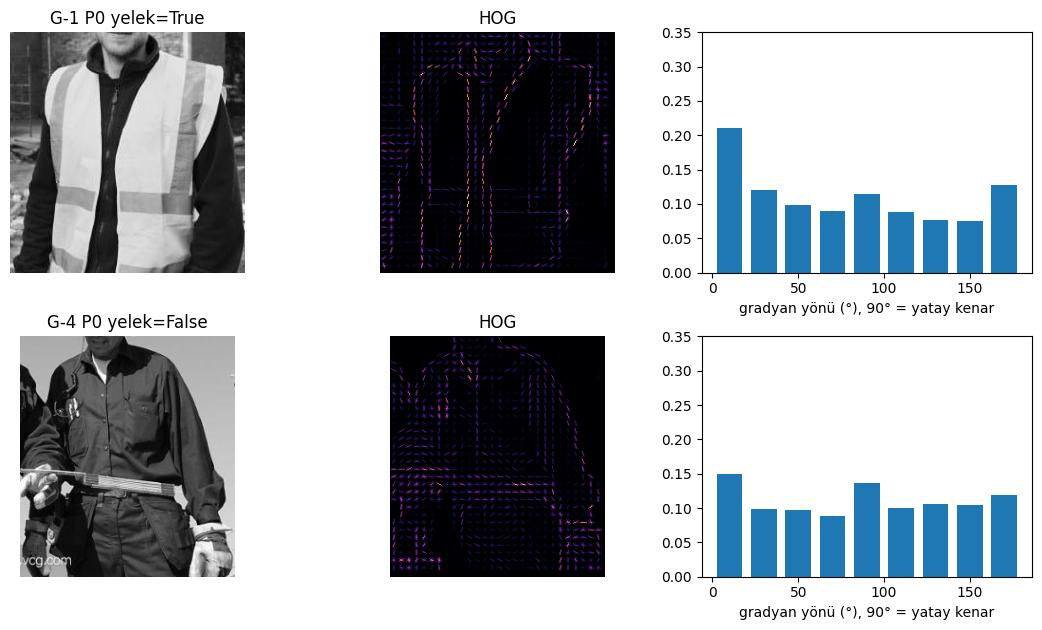

In [13]:
# Bir yelekli ve bir yeleksiz geliştirme gövdesi (G-4 yeleksiz)
hog = features.hog_compare([('G-1', 0), ('G-4', 0)], gt, P, path=RES / 'fig' / 'hog_dev.png')
hog

Açı/ölçek seçimi B dondurmadan önce `params.json`'a yazılır (`save_params(P)`; B'ye haber verin). Sonra features.json kaydedilir:

{'oran_testi': 0.75,
 'ransac_px': 3.0,
 'model': 'homography',
 'kp_A': 188,
 'kp_B': 141,
 'gecen_eslesme': 73,
 'ic_deger': 64,
 'kose_hatasi_px': 0.4819289445877075,
 'kose_hatalari_px': [0.26, 0.33, 0.27, 1.07]}

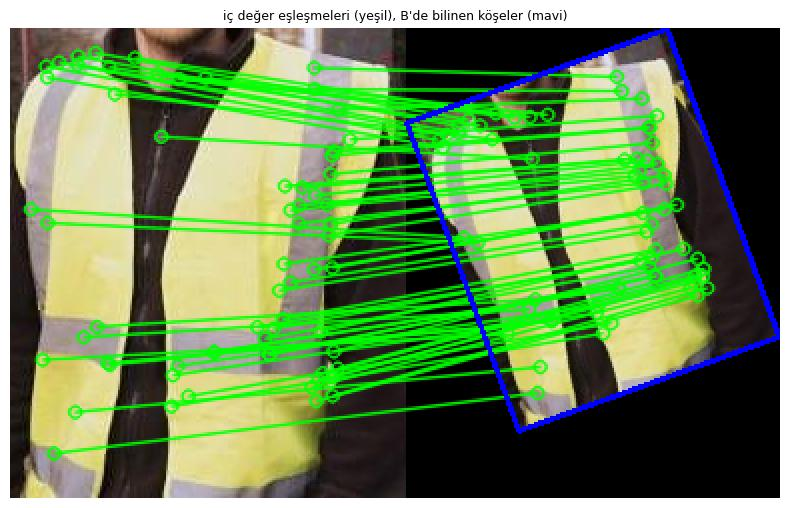

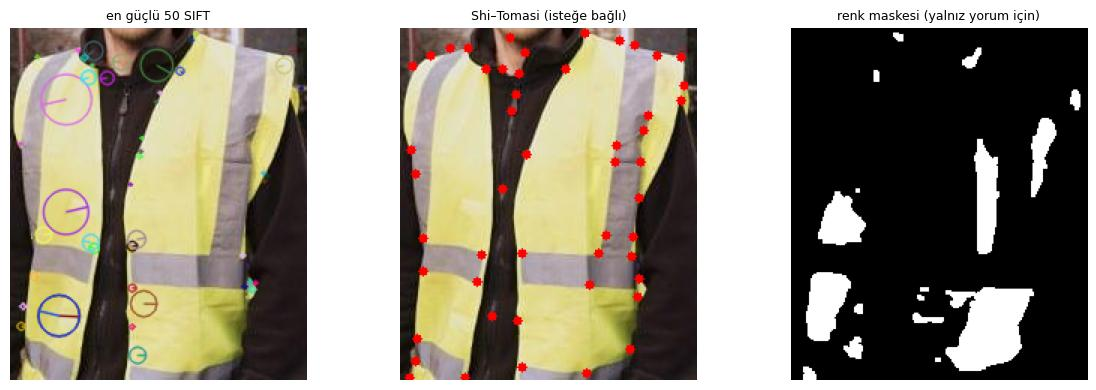

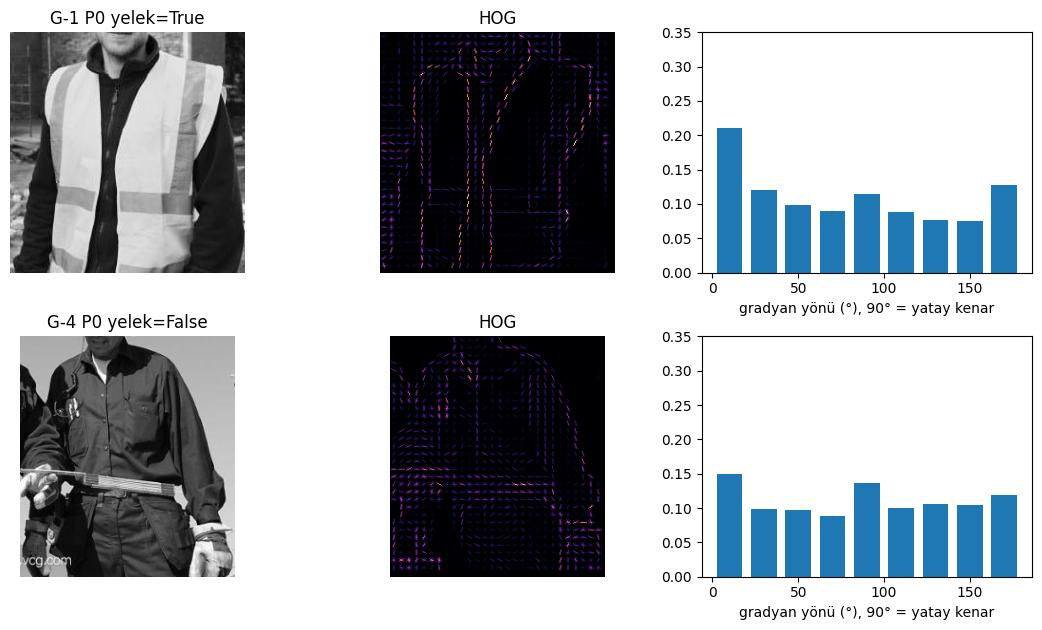

In [14]:
P = load_params()
res, pair = features.run_all(P, gt, hog_items=[('G-1', 0), ('G-4', 0)])
res['7a']

## D6 — Eşleştirme eşiği (oran testi 0,6/0,75/0,9 **ya da** RANSAC 1/3/5 px)
`params.experiments.D6.mode` = `"ratio"` ya da `"ransac"`.

In [15]:
import experiments
d6 = experiments.d6(P, gt, kisi='D')
d6[['oran_testi', 'ransac_px', 'gecen_eslesme', 'ic_deger', 'kose_hatasi_px']]

,oran_testi,ransac_px,gecen_eslesme,ic_deger,kose_hatasi_px
0,0.60,3.0,64,60,0.123972
1,0.75,3.0,73,64,0.481929
2,0.90,3.0,102,68,0.559597
